# Álgebra y funciones: del saldo a la curva

## Objetivo
Distinguir crecimiento simple y compuesto, transformar logaritmos y encontrar raíces sin perder el dominio.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Construir una función

Con capital inicial $V_0=100$ y tasa por periodo $r=0.1$, el modelo simple es $V_t=V_0(1+rt)$ y el compuesto $V_t=V_0(1+r)^t$. En el segundo, cada periodo crece también el interés acumulado. La comparación usa igual tasa y periodicidad.

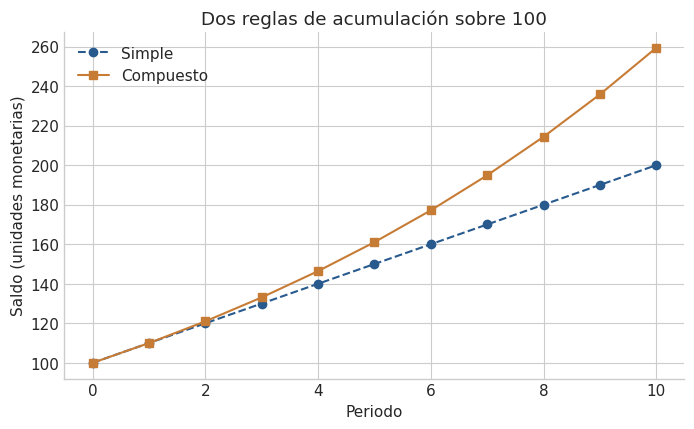

Saldos en periodo 10: 200.00 y 259.37


In [2]:
t=np.arange(11)
simple=100*(1+0.1*t)
compuesto=100*1.1**t
fig,ax=plt.subplots()
ax.plot(t,simple,'o--',label='Simple')
ax.plot(t,compuesto,'s-',label='Compuesto')
ax.set(xlabel='Periodo',ylabel='Saldo (unidades monetarias)',title='Dos reglas de acumulación sobre 100')
ax.legend(); plt.show()
print(f'Saldos en periodo 10: {simple[-1]:.2f} y {compuesto[-1]:.2f}')

**Lectura del resultado.** En el periodo 10 se obtienen 200 y aproximadamente 259.37. La diferencia surge de reinvertir intereses, no de una tasa distinta.

## 2. Linealizar con cuidado

Aplicar logaritmos da $\ln(V_t/V_0)=t\ln(1+r)$. El crecimiento logarítmico por periodo es $\ln(1+r)$, diferente de $r$. La aproximación $\ln(1+r)\approx r$ mejora cerca de cero.

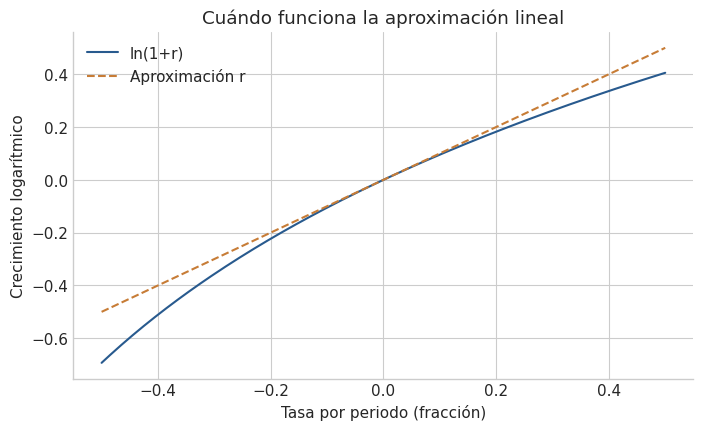

10% simple como log-tasa: 0.09531017980432487


In [3]:
tasas=np.linspace(-0.5,0.5,201)
fig,ax=plt.subplots()
ax.plot(tasas,np.log1p(tasas),label='ln(1+r)')
ax.plot(tasas,tasas,'--',label='Aproximación r')
ax.set(xlabel='Tasa por periodo (fracción)',ylabel='Crecimiento logarítmico',title='Cuándo funciona la aproximación lineal')
ax.legend(); plt.show()
print('10% simple como log-tasa:',np.log1p(0.1))

**Lectura del resultado.** Para 10% el logaritmo es aproximadamente 0.09531. Cerca de -1 la aproximación falla gravemente; el dominio exige r > -1.

## 3. Factorizar y verificar

$x^2-4x+3=(x-1)(x-3)$. Las raíces son puntos donde la curva cruza el eje. Completar el cuadrado, $(x-2)^2-1$, permite ubicar el mínimo.

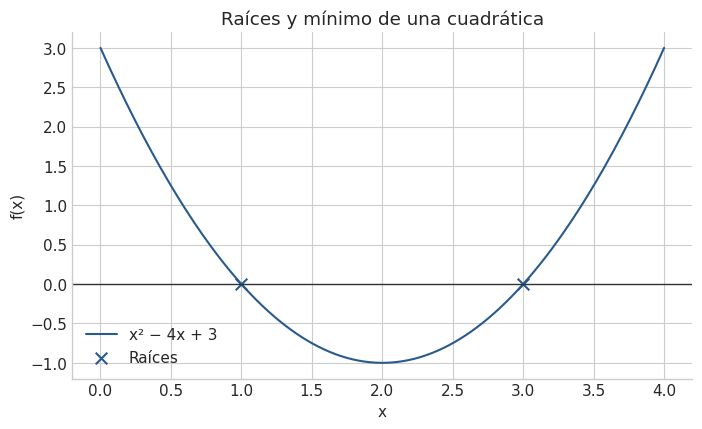

In [4]:
x=np.linspace(0,4,200)
fig,ax=plt.subplots()
ax.plot(x,x*x-4*x+3,label='x² − 4x + 3')
ax.axhline(0,color='#333333',lw=1)
ax.scatter([1,3],[0,0],marker='x',s=70,label='Raíces')
ax.set(xlabel='x',ylabel='f(x)',title='Raíces y mínimo de una cuadrática')
ax.legend(); plt.show()

**Lectura del resultado.** Las raíces 1 y 3 no son el mínimo: el vértice está en x=2, con valor -1.

## Practica antes de ver la solución

¿Cuántos periodos tarda en duplicarse un capital al 5% compuesto? Da la respuesta continua y el primer periodo entero.

In [5]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

De $2=(1.05)^t$, $t=\ln(2)/\ln(1.05)\approx14.21$. El primer periodo entero es 15; comprueba que 14 todavía no alcanza.

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [6]:
assert np.isclose(compuesto[2],121)
assert np.allclose(np.log(compuesto/100),t*np.log1p(.1))
assert 1.05**14 < 2 <= 1.05**15
assert np.allclose(np.polyval([1,-4,3],[1,3]),0)
print('Identidades y umbral de duplicación: OK')

Identidades y umbral de duplicación: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.